In [ ]:
import pandas as pd

data=pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv")
data


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [ ]:
data=data.drop_duplicates()
data=data.dropna(subset=["distance", "fare", "tip"])

# Filter rows where distance and fare are greater than 0
data = data[
    (data["distance"] > 0) &
    (data["fare"] > 0)
]

print(data.shape)

(6382, 14)


In [ ]:
x=data[["distance", "fare", "tip"]]
x

,distance,fare,tip
0,1.60,7.0,2.15
1,0.79,5.0,0.00
2,1.37,7.5,2.36
3,7.70,27.0,6.15
4,2.16,9.0,1.10
...,...,...,...
6428,0.75,4.5,1.06
6429,18.74,58.0,0.00
6430,4.14,16.0,0.00
6431,1.12,6.0,0.00


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test = train_test_split(x, test_size=0.2, random_state=42)


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


In [ ]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)
model.fit(x_train_scaled)

KMeans(n_clusters=3, n_init=10, random_state=42)

In [ ]:
from sklearn.metrics import silhouette_score

labels = model.predict(x_test_scaled)

score = silhouette_score(x_test_scaled, labels)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.545


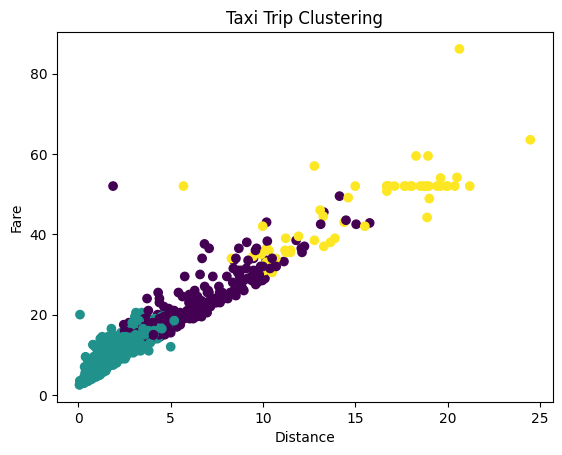

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(
    x_test["distance"],
    x_test["fare"],
    c=labels)
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Taxi Trip Clustering")
plt.show()

In [38]:
# We assign the predicted array directly as a list or numpy array so pandas maps it sequentially to the filtered rows
data["Cluster"] = list(model.predict(scaler.transform(x)))
print(data[["distance", "fare", "tip", "Cluster"]].head(5))

   distance  fare   tip  Cluster
0      1.60   7.0  2.15        1
1      0.79   5.0  0.00        1
2      1.37   7.5  2.36        1
3      7.70  27.0  6.15        0
4      2.16   9.0  1.10        1


In [40]:
cluster_summary=data.groupby("Cluster").agg({
    "distance": ["mean", "median", "min", "max"],
    "fare": ["mean", "median", "min", "max"],
    "tip": ["mean", "median", "min", "max"]
})
cluster_summary

distance                          fare                      \
              mean median   min   max       mean median   min    max   
Cluster                                                                
0         6.437471   5.90  0.11  17.1  23.637663   22.0  12.0   66.0   
1         1.563477   1.34  0.01   9.4   8.621528    8.0   1.0   24.5   
2        15.959541  16.57  0.34  36.7  49.510820   52.0  29.0  150.0   

              tip                     
             mean median  min    max  
Cluster                               
0        3.200134   3.86  0.0   9.39  
1        1.369324   1.50  0.0   7.00  
2        7.771279   9.10  0.0  23.19

In [42]:
cluster_name = {0: "short distance", 1: "long distance", 2: "longest distance"}
data["cluster_name"] = data['Cluster'].map(cluster_name)
print(data[["distance", "fare", "tip", "Cluster", "cluster_name"]].head(5))

   distance  fare   tip  Cluster    cluster_name
0      1.60   7.0  2.15        1   long distance
1      0.79   5.0  0.00        1   long distance
2      1.37   7.5  2.36        1   long distance
3      7.70  27.0  6.15        0  short distance
4      2.16   9.0  1.10        1   long distance
